In [1]:
# Install required packages (skip if already installed)
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

# Car Price Prediction Project

This Jupyter notebook presents a complete machine learning workflow for predicting car prices using the provided dataset. The project follows the requirements from the README and the PDF, covering all essential steps: data loading, cleaning, exploration, feature engineering, model training, evaluation, and deployment.

## 1. Import Required Libraries

We will use pandas, numpy, matplotlib, seaborn, scikit-learn, and joblib for data analysis, visualization, and machine learning.

In [2]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

## 2. Load and Explore Dataset

Let's load the car price dataset and perform initial exploration.

In [3]:
# Load the dataset
file_path = 'car_price_prediction_.csv'
df = pd.read_csv(file_path)

# Display first few rows
df.head()

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


In [4]:
# Check the shape and columns
df.shape, df.columns

((2500, 10),
 Index(['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission',
        'Mileage', 'Condition', 'Price', 'Model'],
       dtype='str'))

In [5]:
# Inspect data types and missing values
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   str    
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   str    
 5   Transmission  2500 non-null   str    
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   str    
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 195.4 KB


Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

## 3. Data Cleaning and Preprocessing

We will clean the data by handling missing values, duplicates, and outliers. We'll also ensure correct data types.

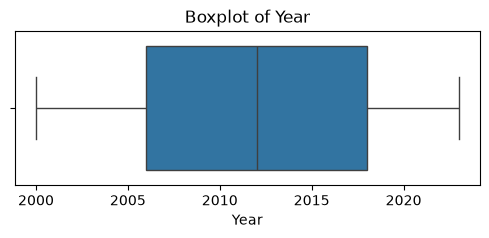

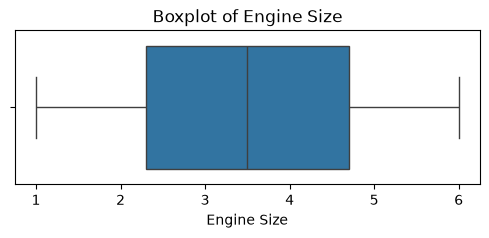

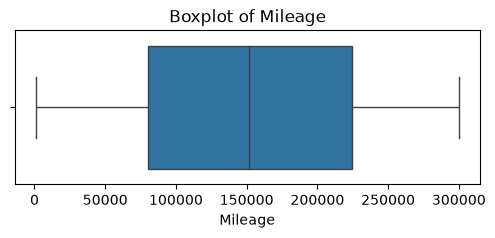

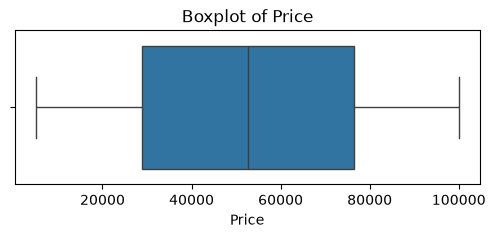

In [6]:
# Remove duplicates
df = df.drop_duplicates()

# Handle missing values (if any)
df = df.dropna()

# Check for outliers in numerical columns
num_cols = ['Year', 'Engine Size', 'Mileage', 'Price']
for col in num_cols:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [7]:
# Convert data types if necessary
df['Year'] = df['Year'].astype(int)
df['Engine Size'] = df['Engine Size'].astype(float)
df['Mileage'] = df['Mileage'].astype(int)
df['Price'] = df['Price'].astype(float)

## 4. Exploratory Data Analysis (EDA)

Let's visualize the distributions and relationships in the data to gain insights.

In [8]:
# Ensure df_encoded exists before EDA heatmap
if 'df_encoded' not in globals():
    categorical_cols = ['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']
    df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

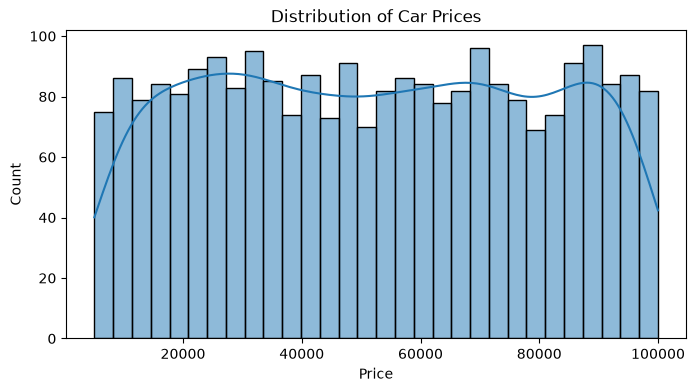

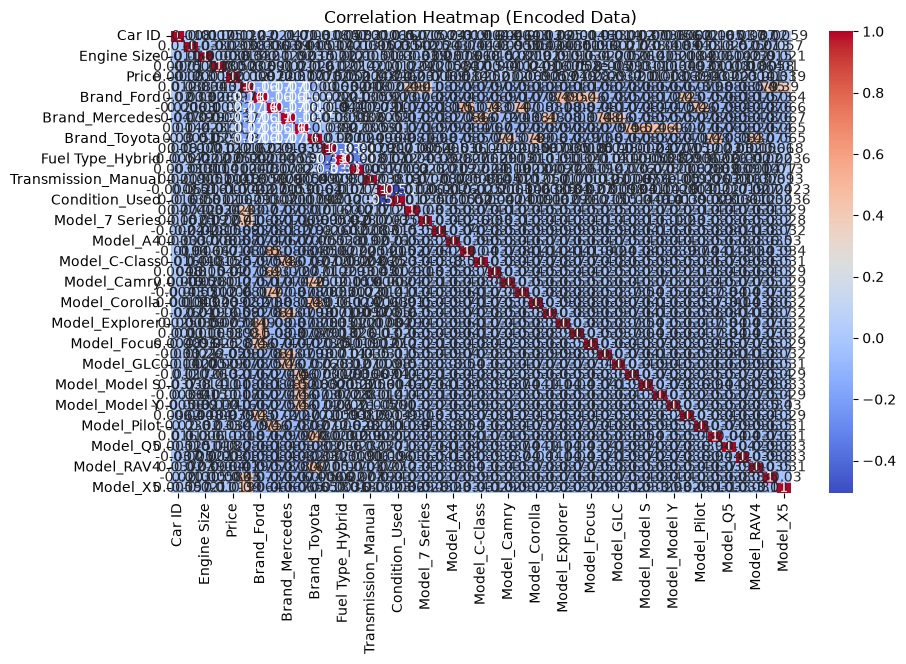

In [9]:
# Distribution of target variable (Price)
plt.figure(figsize=(8,4))
sns.histplot(df['Price'], bins=30, kde=True)
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.show()

# Correlation heatmap (use only numeric columns, and encoded data for correct correlation)
plt.figure(figsize=(10,6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (Encoded Data)')
plt.show()

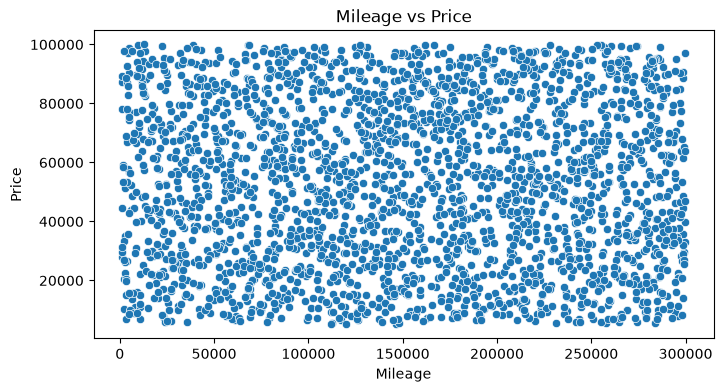

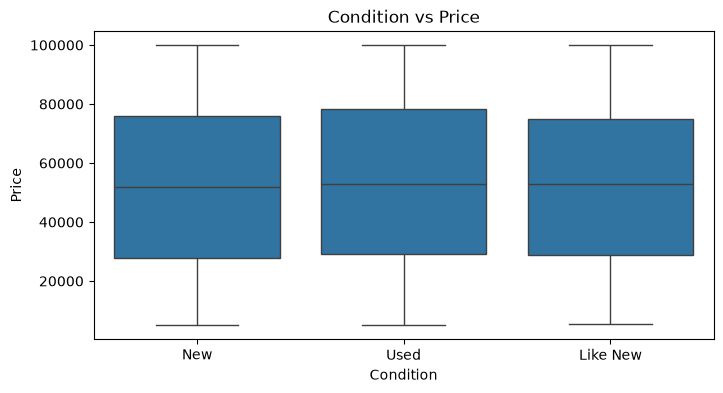

In [10]:
# Scatter plot: Mileage vs Price
plt.figure(figsize=(8,4))
sns.scatterplot(x='Mileage', y='Price', data=df)
plt.title('Mileage vs Price')
plt.show()

# Boxplot: Condition vs Price
plt.figure(figsize=(8,4))
sns.boxplot(x='Condition', y='Price', data=df)
plt.title('Condition vs Price')
plt.show()

## 5. Feature Engineering

Let's create new features and select the most relevant ones for modeling.

In [11]:
# Create car age feature
current_year = 2026
df['Car_Age'] = current_year - df['Year']

# Drop Car ID (not useful for prediction)
df = df.drop('Car ID', axis=1, errors='ignore')

## 6. Encoding Categorical Variables

Encode categorical columns for machine learning models.

In [12]:
# Encode categorical variables
categorical_cols = ['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df_encoded.head()

,Year,Engine Size,Mileage,Price,Car_Age,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Mercedes,Brand_Tesla,...,Model_Model X,Model_Model Y,Model_Mustang,Model_Pilot,Model_Prius,Model_Q5,Model_Q7,Model_RAV4,Model_X3,Model_X5
0,2016,2.3,114832,26613.92,10,False,False,False,False,True,...,True,False,False,False,False,False,False,False,False,False
1,2018,4.4,143190,14679.61,8,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2013,4.5,181601,44402.61,13,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,2011,4.1,68682,86374.33,15,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False
4,2009,2.6,223009,73577.10,17,False,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False


## 7. Train-Test Split

Split the data into training and testing sets for model evaluation.

In [13]:
# Split features and target
X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

Train shape: (2000, 44)
Test shape: (500, 44)


## 8. Model Selection and Training

We will train several regression models and compare their performance.

In [14]:
# Train Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# Train Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# Train Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

## 9. Model Evaluation

Evaluate the models using MAE, MSE, and R-squared. Visualize predicted vs actual prices.

Linear Regression:
MAE: 24761.02, MSE: 797676283.96, R2: -0.01


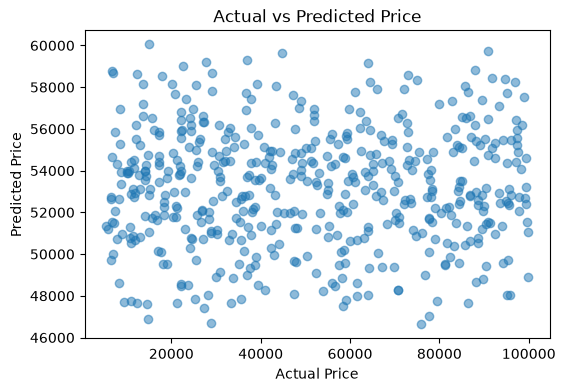

Random Forest:
MAE: 25022.28, MSE: 837963265.95, R2: -0.07


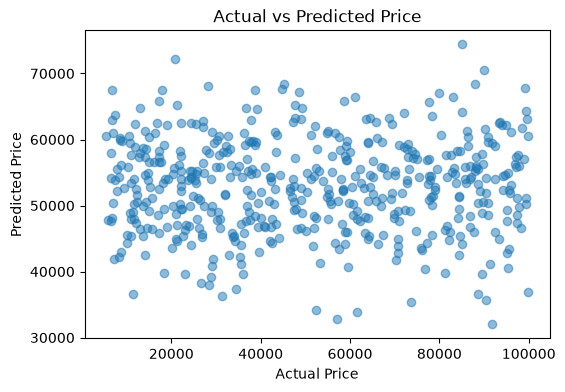

Gradient Boosting:
MAE: 24546.67, MSE: 800933501.17, R2: -0.02


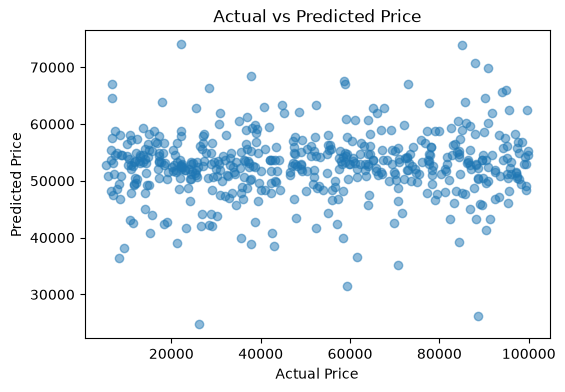

(24546.67159526135, 800933501.1739434, -0.01867772795221012)

In [15]:
# Evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"MAE: {mae:.2f}, MSE: {mse:.2f}, R2: {r2:.2f}")
    plt.figure(figsize=(6,4))
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.title('Actual vs Predicted Price')
    plt.show()
    return mae, mse, r2

print('Linear Regression:')
evaluate_model(lr, X_test, y_test)
print('Random Forest:')
evaluate_model(rf, X_test, y_test)
print('Gradient Boosting:')
evaluate_model(gb, X_test, y_test)

## 10. Hyperparameter Tuning

Optimize model hyperparameters using GridSearchCV for better performance.

In [16]:
# Hyperparameter tuning for Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
gs_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=3, scoring='r2', n_jobs=-1)
gs_rf.fit(X_train, y_train)
print('Best parameters:', gs_rf.best_params_)
print('Best score:', gs_rf.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best score: -0.04934375412841874


## 11. Model Interpretation

Interpret feature importances to understand which factors most influence car prices.

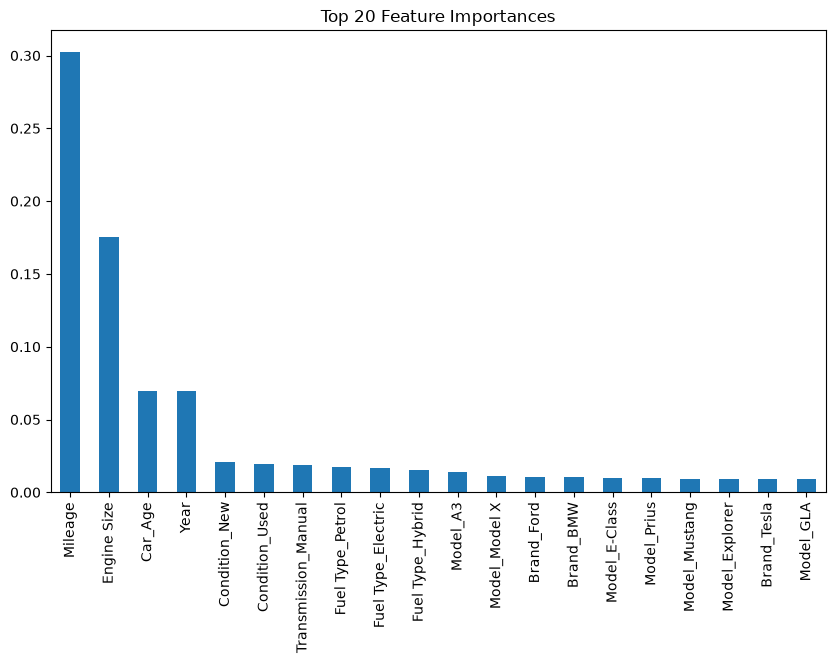

In [17]:
# Feature importances from best Random Forest
importances = gs_rf.best_estimator_.feature_importances_
features = X_train.columns
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)
plt.figure(figsize=(10,6))
feat_imp[:20].plot(kind='bar')
plt.title('Top 20 Feature Importances')
plt.show()

## 12. Prediction on New Data

Use the trained model to predict prices for new car samples.

In [18]:
# Example: Predict price for a new car
new_car = X_test.iloc[[0]]  # Use one sample from test set as example
predicted_price = gs_rf.predict(new_car)
print('Predicted price:', predicted_price[0])

Predicted price: 49791.98779126094


## 13. Save and Load Model

Save the trained model for future use and demonstrate loading it.

In [19]:
# Save the trained model
joblib.dump(gs_rf.best_estimator_, 'car_price_rf_model.joblib')

# Load the model and predict again
loaded_model = joblib.load('car_price_rf_model.joblib')
loaded_pred = loaded_model.predict(new_car)
print('Loaded model predicted price:', loaded_pred[0])

Loaded model predicted price:

 49791.98779126094


# Project Summary

This notebook demonstrated a complete workflow for car price prediction using machine learning. We covered data loading, cleaning, EDA, feature engineering, encoding, model training, evaluation, hyperparameter tuning, interpretation, prediction, and model saving/loading. You can now use this notebook as a template for similar regression projects.